# EN3160 Assignment 02
## Fitting and Alignment

**Name:** Rahman MFA  
**Index number:** 230507R  
**Repository:** [EN3160 Image Processing and Machine Vision](https://github.com/Abdul-Rahman-bme/EN3160-Image-processing-and-Machine-Vision)


This notebook follows the same question-by-question workflow as Assignment 1. We will run each part, inspect the output, and then write a short discussion based on the actual results.

**Before running:** put the provided Assignment 2 images in the `images` folder next to this notebook.

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import maximum_filter
from scipy.optimize import minimize

IMAGE_DIR = Path("images/a2images")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("OpenCV version:", cv.__version__)
print("NumPy version:", np.__version__)
print("Image folder:", IMAGE_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

OpenCV version: 5.0.0
NumPy version: 2.4.6
Image folder: D:\Abdul Rahman\Engineering_UOM\.Sem 5\EN3160 - Image Processing and Computer Vision\EN3160-Image-processing-and-Machine-Vision\Assignment_02\images\a2images
Output folder: D:\Abdul Rahman\Engineering_UOM\.Sem 5\EN3160 - Image Processing and Computer Vision\EN3160-Image-processing-and-Machine-Vision\Assignment_02\outputs


## Q1 — Sunflower blob detection using LoG

We will load the sunflower image at the reduced resolution specified in the assignment. After confirming the image loads correctly, we will implement the LoG scale-space detector. The `cv.HoughCircles()` function will not be used.

Image dimensions (height, width): (360, 360)


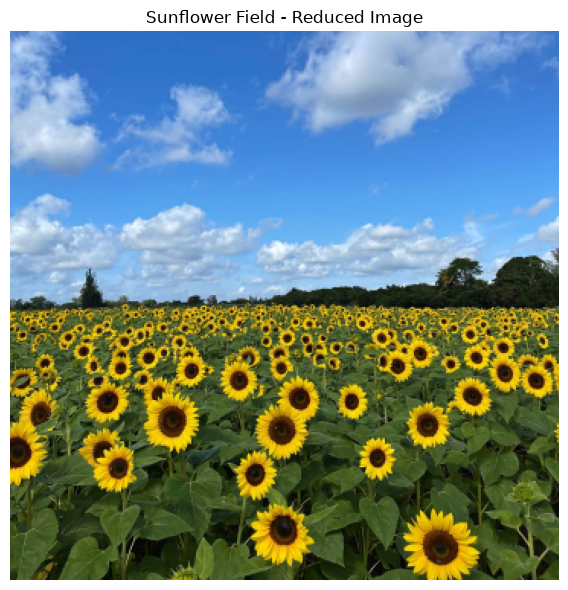

In [3]:
# Q1 - Load and display the sunflower image

sunflower_path = IMAGE_DIR / "the_berry_farms_sunflower_field.jpeg"
sunflower = cv.imread(str(sunflower_path), cv.IMREAD_REDUCED_COLOR_4)

if sunflower is None:
    raise FileNotFoundError(
        f"Could not load {sunflower_path.resolve()}. "
        "Check that the image is inside the images folder."
    )

sunflower_rgb = cv.cvtColor(sunflower, cv.COLOR_BGR2RGB)
sunflower_gray = cv.cvtColor(sunflower, cv.COLOR_BGR2GRAY)

print("Image dimensions (height, width):", sunflower_gray.shape)

plt.figure(figsize=(10, 6))
plt.imshow(sunflower_rgb)
plt.title("Sunflower Field - Reduced Image")
plt.axis("off")
plt.tight_layout()
plt.show()

In [4]:

#Q1 - LoG detection with non-maximum suppression

# Find stronger local maxima in position and scale
local_max = maximum_filter(responses, size=(3, 9, 9))

threshold = 0.20 * responses.max()

s, y, x = np.where(
    (responses == local_max) &
    (responses > threshold)
)

# Store candidates as (x, y, sigma, response)
candidates = [
    (int(xi), int(yi), float(sigmas[si]),
     float(responses[si, yi, xi]))
    for si, yi, xi in zip(s, y, x)
]
# Keep detections within the sunflower field
candidates = [b for b in candidates if b[1] >= 225]

candidates.sort(key=lambda b: b[3], reverse=True)

# Non-maximum suppression
blobs = []

for candidate in candidates:
    x, y, sigma, score = candidate
    radius = np.sqrt(2) * sigma

    keep = True

    for bx, by, bsigma, bscore in blobs:
        other_radius = np.sqrt(2) * bsigma
        distance = np.hypot(x - bx, y - by)

        min_distance = max(8.0, radius + other_radius)

        if distance < min_distance:
            keep = False
            break

    if keep:
        blobs.append(candidate)

# Visualise the strongest detections
result = sunflower_rgb.copy()

for x, y, sigma, score in blobs[:200]:
    radius = max(2, int(np.sqrt(2) * sigma))
    cv.circle(result, (x, y), radius, (255, 0, 0), 1)

plt.figure(figsize=(10, 7))
plt.imshow(result)
plt.title("Sunflower Blob Detection using LoG and NMS")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Candidates before NMS:", len(candidates))
print("Detections after NMS:", len(blobs))
print("Strongest detections (x, y, sigma, response):")
print(blobs[:10])


NameError: name 'responses' is not defined

The Laplacian of Gaussian (LoG) method was used to detect blob-like structures at different scales in the sunflower image. Scale normalization allowed the responses at different scales to be compared. Local maxima were selected as candidate detections, and non-maximum suppression reduced overlapping circles. Restricting the search to the sunflower field removed detections from the sky and most of the trees. However, some false detections remained on leaves and petals because LoG responds to intensity structures rather than specifically identifying flowers. The final result therefore demonstrates blob detection, but it is not a count of the actual number of sunflowers.

## Q2 — RANSAC line and circle fitting

We will generate the noisy point set described in Listing 1 of the assignment. We will implement RANSAC ourselves, estimate a normalized line model first, remove its inliers, and then estimate a circle from the remaining points. The final plot will show the point set, inliers, best samples, estimated models, and ground-truth models.

In [ ]:

# Q2 - Generate the noisy point set
from scipy.optimize import minimize
from matplotlib.patches import Circle

np.random.seed(0)  # Keep the results the same when rerunning

N = 100
half_n = N // 2

# Points around a circle
r_gt = 10
x0_gt, y0_gt = 2, 3
noise_c = r_gt / 16

t = np.random.uniform(0, 2*np.pi, half_n)
n = noise_c * np.random.randn(half_n)

X_circ = np.column_stack((
    x0_gt + (r_gt+n)*np.cos(t),
    y0_gt + (r_gt+n)*np.sin(t)
))

# Points around a straight line
m_gt, b_gt = -1, 2
x_line = np.linspace(-12, 12, half_n)
y_line = m_gt*x_line + b_gt + np.random.randn(half_n)

X_line = np.column_stack((x_line, y_line))
X = np.vstack((X_circ, X_line))

print("Total number of points:", len(X))


Total number of points: 100


In [ ]:

# Fit a line using two points
def line_from_pair(p1, p2):
    v = p2 - p1
    length = np.linalg.norm(v)
    if length < 1e-8:
        return None

    normal = np.array([-v[1], v[0]]) / length
    d = normal @ p1
    return np.array([normal[0], normal[1], d])


def line_error(points, model):
    return np.abs(points @ model[:2] - model[2])


# Refine the line using total least squares
def fit_tls_line(points):
    centre = points.mean(axis=0)
    _, _, vh = np.linalg.svd(points - centre, full_matrices=False)
    direction = vh[0]
    normal = np.array([-direction[1], direction[0]])
    return np.array([normal[0], normal[1], normal @ centre])


# RANSAC parameters
line_threshold = 1.5
min_line_inliers = 35
best_line_count = 0

for _ in range(2000):
    ids = np.random.choice(len(X), 2, replace=False)
    model = line_from_pair(X[ids[0]], X[ids[1]])
    if model is None:
        continue

    inliers = line_error(X, model) <= line_threshold
    count = inliers.sum()

    if count >= min_line_inliers and count > best_line_count:
        best_line_count = count
        best_line_sample_model = model
        best_line_sample = X[ids].copy()

# Refine the best line using its inliers
line_inliers = line_error(X, best_line_sample_model) <= line_threshold
best_fit_line = fit_tls_line(X[line_inliers])
line_inliers = line_error(X, best_fit_line) <= line_threshold
best_fit_line = fit_tls_line(X[line_inliers])

a, b, d = best_fit_line
print(f"Line inliers: {line_inliers.sum()}")
print(f"Best-fit line: {a:.3f}x + {b:.3f}y = {d:.3f}")
print(f"Normal vector length: {np.linalg.norm([a, b]):.3f}")


Line inliers: 54
Best-fit line: 0.721x + 0.693y = 1.572
Normal vector length: 1.000


In [ ]:

# Remove the points belonging to the line
remaining = X[~line_inliers]


def circle_from_three(points):
    p1, p2, p3 = points
    A = 2*np.vstack((p2-p1, p3-p1))
    rhs = np.array([p2@p2-p1@p1, p3@p3-p1@p1])

    if abs(np.linalg.det(A)) < 1e-8:
        return None

    cx, cy = np.linalg.solve(A, rhs)
    r = np.linalg.norm(p1 - [cx, cy])
    return np.array([cx, cy, r])


def circle_error(points, model):
    return np.abs(np.linalg.norm(points-model[:2], axis=1) - model[2])


# RANSAC for the circle
circle_threshold = 1.25
min_circle_inliers = 30
best_circle_count = 0

for _ in range(2000):
    ids = np.random.choice(len(remaining), 3, replace=False)
    sample = remaining[ids]
    model = circle_from_three(sample)
    if model is None:
        continue

    inliers = circle_error(remaining, model) <= circle_threshold
    count = inliers.sum()

    if count >= min_circle_inliers and count > best_circle_count:
        best_circle_count = count
        best_circle_sample_model = model
        best_circle_sample = sample.copy()

# Refine the circle using its inliers
circle_inliers = circle_error(
    remaining, best_circle_sample_model
) <= circle_threshold
circle_points = remaining[circle_inliers]


def circle_loss(params, points):
    errors = np.linalg.norm(points-params[:2], axis=1) - params[2]
    return np.sum(errors**2)


opt = minimize(
    circle_loss, best_circle_sample_model, args=(circle_points,),
    bounds=[(None, None), (None, None), (1e-6, None)]
)
best_fit_circle = opt.x

# Show the final estimates
cx, cy, radius = best_fit_circle
print(f"Circle inliers: {circle_inliers.sum()}")
print(f"Centre: ({cx:.3f}, {cy:.3f})")
print(f"Radius: {radius:.3f}")


Circle inliers: 46
Centre: (1.949, 2.988)
Radius: 9.892


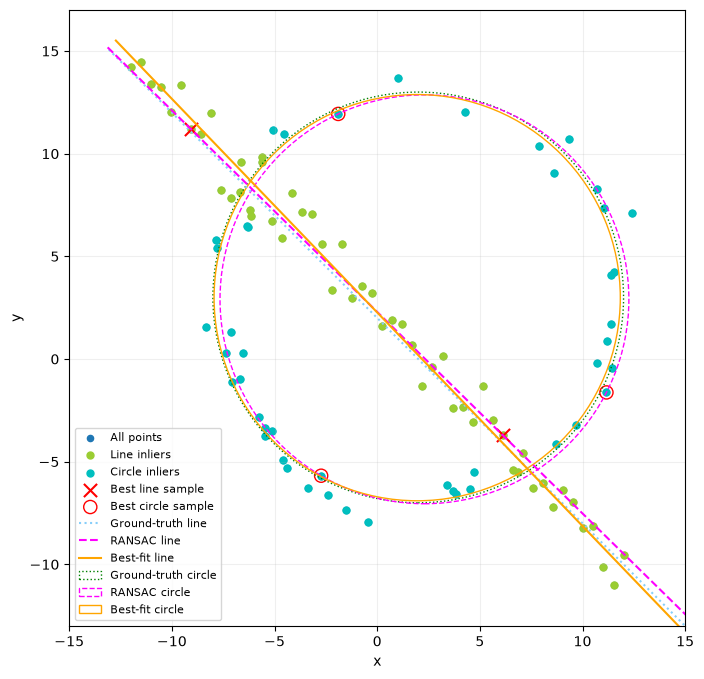

In [ ]:

# Draw the fitted models and compare them with the original points
def draw_line(ax, model, label, color, style="-"):
    a, b, d = model
    normal = np.array([a, b])
    point = d * normal
    direction = np.array([-b, a])
    t = np.linspace(-20, 20, 100)
    line = point + t[:, None]*direction
    ax.plot(line[:, 0], line[:, 1], color=color,
            linestyle=style, label=label)


def draw_circle(ax, model, label, color, style="-"):
    cx, cy, r = model
    ax.add_patch(Circle((cx, cy), r, fill=False,
                        color=color, linestyle=style, label=label))


fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(X[:, 0], X[:, 1], s=20, label="All points")
ax.scatter(X[line_inliers, 0], X[line_inliers, 1],
           s=25, color="yellowgreen", label="Line inliers")
ax.scatter(circle_points[:, 0], circle_points[:, 1],
           s=25, color="c", label="Circle inliers")

ax.scatter(best_line_sample[:, 0], best_line_sample[:, 1],
           marker="x", s=90, color="red", label="Best line sample")
ax.scatter(best_circle_sample[:, 0], best_circle_sample[:, 1],
           marker="o", s=90, facecolors="none",
           edgecolors="red", label="Best circle sample")

# Sample-based and refined lines
line_gt = np.array([1/np.sqrt(2), 1/np.sqrt(2), 2/np.sqrt(2)])
draw_line(ax, line_gt, "Ground-truth line", "lightskyblue", ":")
draw_line(ax, best_line_sample_model, "RANSAC line", "magenta", "--")
draw_line(ax, best_fit_line, "Best-fit line", "orange")

# Sample-based and refined circles
draw_circle(ax, [x0_gt, y0_gt, r_gt],
            "Ground-truth circle", "green", ":")
draw_circle(ax, best_circle_sample_model,
            "RANSAC circle", "magenta", "--")
draw_circle(ax, best_fit_circle, "Best-fit circle", "orange")

ax.set_xlim(-15, 15)
ax.set_ylim(-13, 17)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.grid(True, alpha=0.2)
ax.legend(fontsize=8)
plt.show()


If the circle is fitted first, RANSAC may find the correct circle, but there is also a risk of fitting a very large-radius circle to the points belonging to the straight line. A sufficiently large circle can approximate a line over a limited distance. The result depends on the sampling, error threshold and consensus size. Fitting the line first removes its inliers and leaves a cleaner set of points for circle estimation. However, fitting the circle first is not guaranteed to fail; it can also work with suitable parameters.

## Q3 — Homography and image compositing

We will select four points on a planar surface, compute the homography from the flag image to that quadrilateral, warp the flag, and blend it with the architectural image. We will use a couple of image pairs and briefly explain why each surface is suitable.

Flag size: (960, 1920, 3)
Building size: (768, 1024, 3)


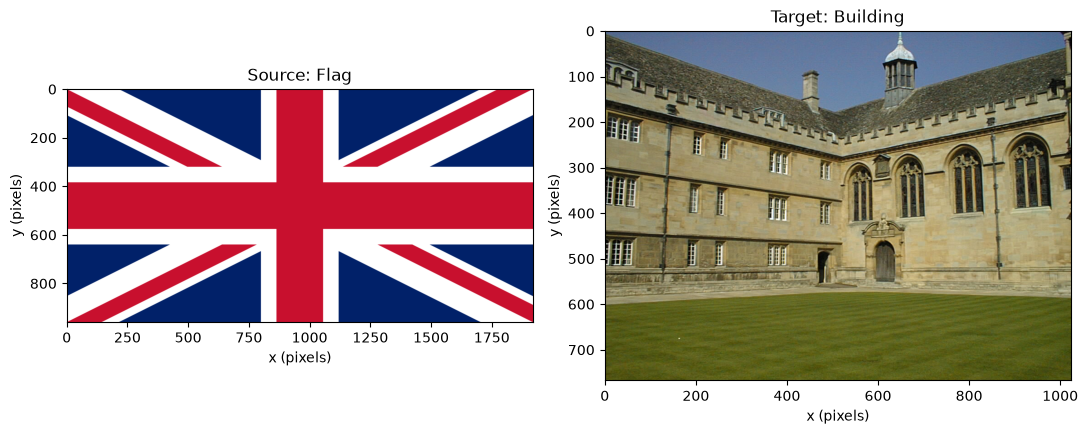

In [ ]:

# Q3 - Load the flag and building images
flag = cv.imread(str(IMAGE_DIR / "flag.png"))
building = cv.imread(str(IMAGE_DIR / "wadham.jpg"))

if flag is None or building is None:
    raise FileNotFoundError("Check the image filenames and folder paths.")

flag_rgb = cv.cvtColor(flag, cv.COLOR_BGR2RGB)
building_rgb = cv.cvtColor(building, cv.COLOR_BGR2RGB)

print("Flag size:", flag.shape)
print("Building size:", building.shape)

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(flag_rgb)
ax[0].set_title("Source: Flag")
ax[1].imshow(building_rgb)
ax[1].set_title("Target: Building")

for a in ax:
    a.set_xlabel("x (pixels)")
    a.set_ylabel("y (pixels)")

plt.tight_layout()
plt.show()


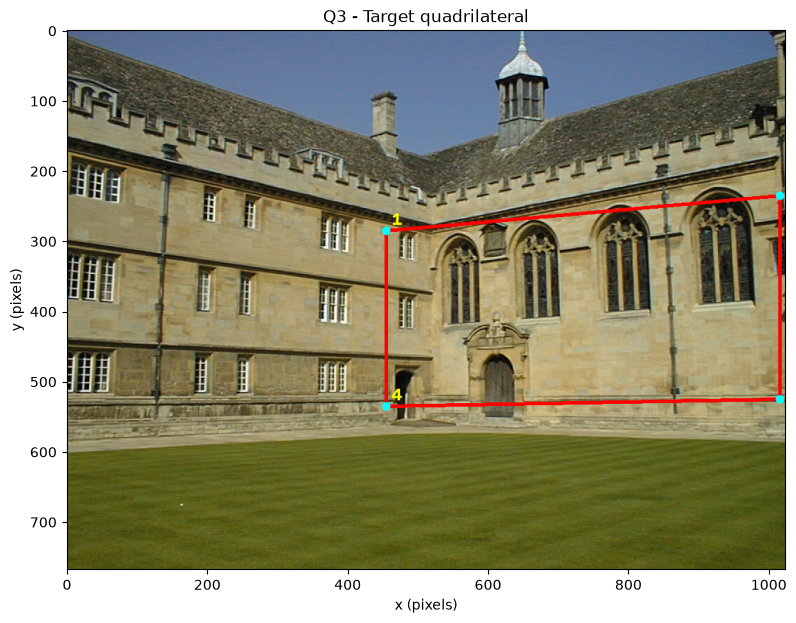

In [ ]:
# Q3 - Select the target quadrilateral on the building

building_h, building_w = building.shape[:2]

dst_pts = np.float32([
    [455, 285],                 # Top-left
    [building_w - 8, 235],      # Top-right
    [building_w - 8, 525],      # Bottom-right
    [455, 535]                  # Bottom-left
])

preview = building_rgb.copy()

cv.polylines(
    preview,
    [dst_pts.astype(np.int32)],
    True,
    (255, 0, 0),
    3
)

for i, (x, y) in enumerate(dst_pts, start=1):
    cv.circle(preview, (int(x), int(y)), 6, (0, 255, 255), -1)
    cv.putText(
        preview, str(i), (int(x) + 8, int(y) - 8),
        cv.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 0), 2
    )

plt.figure(figsize=(10, 7))
plt.imshow(preview)
plt.title("Q3 - Target quadrilateral")
plt.xlabel("x (pixels)")
plt.ylabel("y (pixels)")
plt.show()

Homography matrix:
[[ 2.19313220e-01 -8.61006027e-17  4.55000000e+02]
 [-4.29462184e-02  2.60688217e-01  2.85000000e+02]
 [-7.18765161e-05 -1.17064042e-19  1.00000000e+00]]


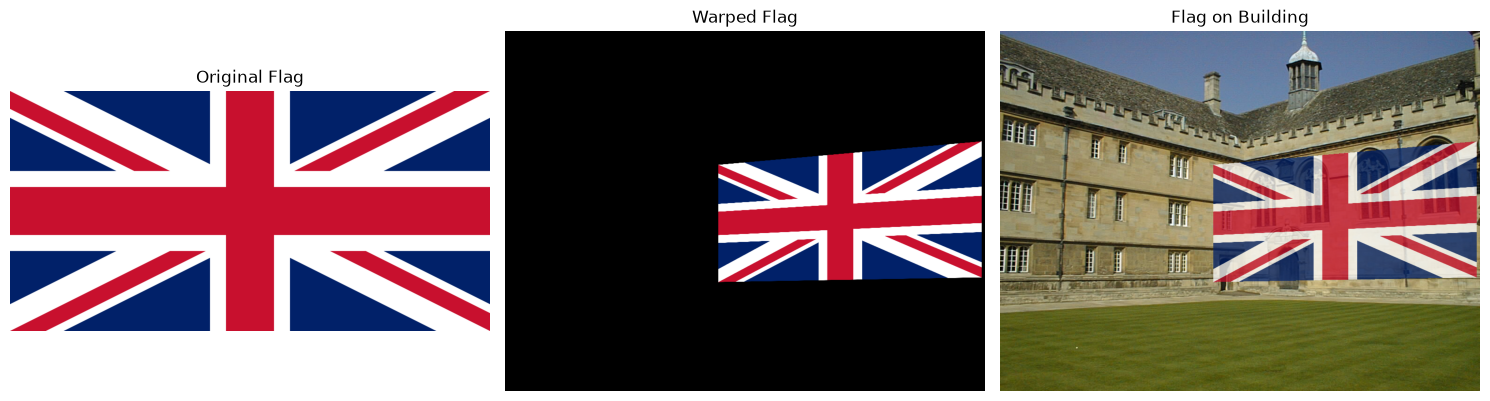

True

In [ ]:
# Q3 - Calculate homography and warp the flag

flag_h, flag_w = flag.shape[:2]

# Four corners of the original flag
src_pts = np.float32([
    [0, 0],
    [flag_w - 1, 0],
    [flag_w - 1, flag_h - 1],
    [0, flag_h - 1]
])

# Map the flag corners to the building corners
H, status = cv.findHomography(src_pts, dst_pts)

if H is None:
    raise ValueError("Could not calculate the homography.")

print("Homography matrix:")
print(H)

# Warp the flag into the building image
warped_flag = cv.warpPerspective(
    flag, H, (building_w, building_h)
)

# Warp a mask so we know which pixels belong to the flag
flag_mask = np.full((flag_h, flag_w), 255, dtype=np.uint8)

warped_mask = cv.warpPerspective(
    flag_mask, H, (building_w, building_h),
    flags=cv.INTER_NEAREST
)

mask = warped_mask > 0

# Blend the flag with the original building
alpha = 0.75
result = building.copy()

result[mask] = cv.addWeighted(
    warped_flag[mask], alpha,
    building[mask], 1 - alpha, 0
)

# Display the results
warped_rgb = cv.cvtColor(warped_flag, cv.COLOR_BGR2RGB)
result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(flag_rgb)
ax[0].set_title("Original Flag")

ax[1].imshow(warped_rgb)
ax[1].set_title("Warped Flag")

ax[2].imshow(result_rgb)
ax[2].set_title("Flag on Building")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

# Save the composite for later use in the report
cv.imwrite(
    str(OUTPUT_DIR / "q3_flag_on_right_facade.png"),
    result
)

### Homography and Image Compositing

The homography matrix was calculated using the four corners of the original flag and the corresponding points selected on the building. The flag was then warped to match the perspective of the selected region.

A mask was used to identify the pixels belonging to the warped flag, preventing the black background from replacing the original building image. Finally, alpha blending was applied to combine the flag with the building. An alpha value of 0.75 gives the flag a slightly transparent appearance while preserving some of the details underneath it.

This method demonstrates how a projective transformation can be used to place an image onto a surface in another image. However, it assumes a planar surface and does not account for occlusion by architectural features.

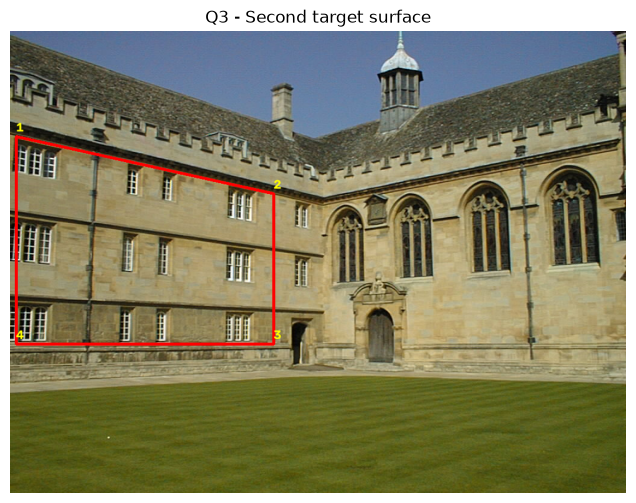

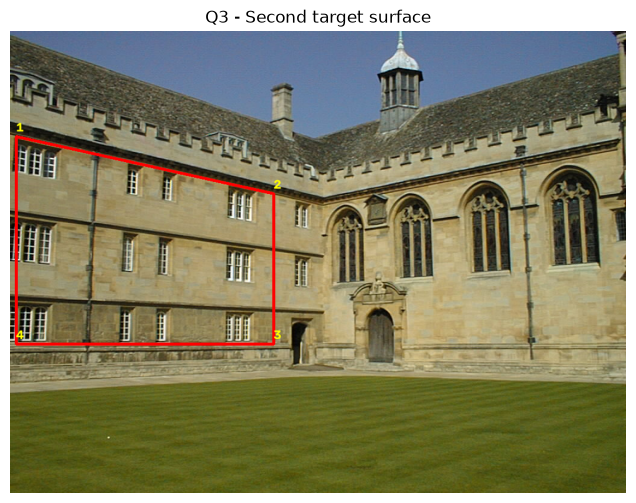

In [6]:

# Q3 - Select another surface for the second example

sunflower = cv.imread(
    str(IMAGE_DIR / "the_berry_farms_sunflower_field.jpeg")
)

# Approximate corners of the left building façade
dst_pts2 = np.float32([
    [10, 175],    # Top-left
    [438, 270],   # Top-right
    [438, 520],   # Bottom-right
    [10, 520]     # Bottom-left
])


# Load the building image
building_bgr = cv.imread(str(IMAGE_DIR / "wadham.jpg"))

if building_bgr is None:
    raise FileNotFoundError("Could not load wadham.jpg. Check IMAGE_DIR.")

building_rgb = cv.cvtColor(building_bgr, cv.COLOR_BGR2RGB)

# Draw the selected quadrilateral
preview2 = building_rgb.copy()

cv.polylines(
    preview2,
    [dst_pts2.astype(np.int32)],
    True,
    (255, 0, 0),
    3
)

for i, (x, y) in enumerate(dst_pts2, 1):
    cv.putText(
        preview2, str(i),
        (int(x), int(y) - 8),
        cv.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 0),
        2
    )

plt.figure(figsize=(9, 6))
plt.imshow(preview2)
plt.title("Q3 - Second target surface")
plt.axis("off")
plt.show()


preview2 = building_rgb.copy()
cv.polylines(preview2, [dst_pts2.astype(np.int32)],
             True, (255, 0, 0), 3)

for i, (x, y) in enumerate(dst_pts2, 1):
    cv.putText(preview2, str(i), (int(x), int(y) - 8),
               cv.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 0), 2)

plt.figure(figsize=(9, 6))
plt.imshow(preview2)
plt.title("Q3 - Second target surface")
plt.axis("off")
plt.show()


## Q4 — PCB image alignment

Using `AECC1.jpg` as the template, we will detect SIFT features, match them with `cv.BFMatcher`, estimate a homography with RANSAC, warp each supplied PCB image, and visualize the difference from the template. We will then discuss why some components may show larger differences.

## Report notes

- Keep the final report to four pages or fewer.
- Include the index number and name.
- Show important code, result images, comparisons, and interpretation.
- Commit and push progress regularly.